# Example SIRDS model

We use a stochastic SIRDS
(Susceptible–Infected–Recovered–Dead–Susceptible) compartmental model as
a running example throughout the docs. The particulars of how this model
work aren’t too important, but the basic idea is that our simulator
depends on some static input parameters (I0, beta, etc…) and produces
stochastic timeseries of compartment counts over time.

## Code definition

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def simulate_sirds(
    I0=0.005, beta=0.4, gamma=0.1, omega=0.02, mu=0.01, T=365, dt=1.0, N=1000, seed=None
):
    rng = np.random.default_rng(seed)
    n = int(T / dt) + 1
    I0_count = max(0, min(N, int(round(I0 * N))))

    S = np.zeros(n, dtype=np.int32)
    I = np.zeros(n, dtype=np.int32)
    R = np.zeros(n, dtype=np.int32)
    D = np.zeros(n, dtype=np.int32)
    S[0], I[0], R[0], D[0] = N - I0_count, I0_count, 0, 0

    for k in range(n - 1):
        p_inf = 1.0 - np.exp(-beta * I[k] / N * dt)
        p_rec = 1.0 - np.exp(-gamma * dt)
        p_die = 1.0 - np.exp(-mu * dt)
        p_sus = 1.0 - np.exp(-omega * dt)

        new_I = rng.binomial(S[k], p_inf)

        # Competing risks: each infected individual can recover, die, or stay infected.
        # Use a multinomial draw so recovery + death never exceeds I[k].
        p_stay = max(0.0, 1.0 - p_rec - p_die)
        outcomes = rng.multinomial(I[k], [p_rec, p_die, p_stay])
        new_R = outcomes[0]
        new_D = outcomes[1]

        new_S = rng.binomial(R[k], p_sus)

        S[k + 1] = S[k] - new_I + new_S
        I[k + 1] = I[k] + new_I - new_R - new_D
        R[k + 1] = R[k] + new_R - new_S
        D[k + 1] = D[k] + new_D

    return S, I, R, D

## Example realisations

Here we again emphasise that even with fixed input parameters, varying
the random seed produces different realisations.

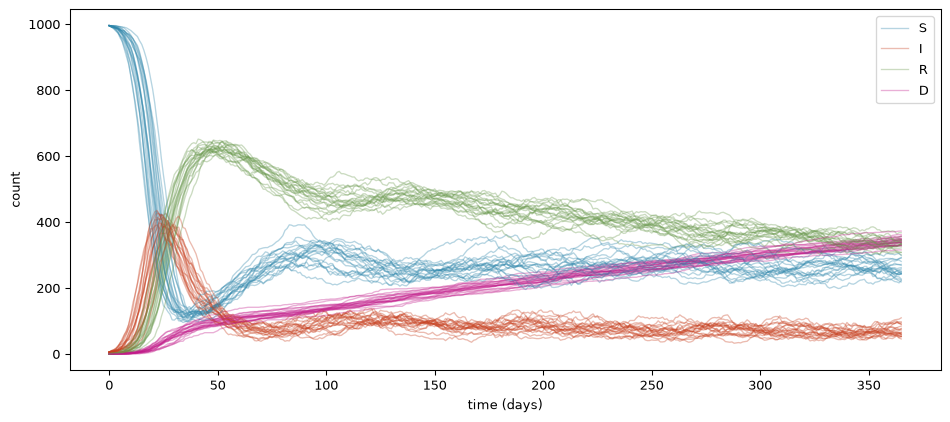

In [2]:
fig, ax = plt.subplots(1, 1, figsize=(10, 4.5))
for s in range(20):
    S, I, R, D = simulate_sirds(seed=s)
    t = np.arange(len(S))
    ax.plot(t, S, color="#2E86AB", label="S" if s == 0 else None, alpha=0.35, lw=1)
    ax.plot(t, I, color="#C73E1D", label="I" if s == 0 else None, alpha=0.35, lw=1)
    ax.plot(t, R, color="#6A994E", label="R" if s == 0 else None, alpha=0.35, lw=1)
    ax.plot(t, D, color="#C21B8A", label="D" if s == 0 else None, alpha=0.35, lw=1)
ax.set(
    xlabel="time (days)",
    ylabel="count",
    title="",
)
ax.legend()

plt.tight_layout()
plt.show()